In [1]:
from src.config import  ANALYTICAL_DATA_PATH
from src.styles import NHS_COLORS

import pandas as pd
import matplotlib.pyplot as plt
from utilsforecast.plotting import plot_series
from utilsforecast.evaluation import evaluate
from utilsforecast.losses import *
from statsforecast.models import Naive, ARIMA, AutoARIMA, HistoricAverage, SeasonalNaive, WindowAverage
from statsforecast import StatsForecast



/Users/pro2020/projects/python/nhs-waiting-list /Users/pro2020/projects/python/nhs-waiting-list/data/raw /Users/pro2020/projects/python/nhs-waiting-list/data/processed


In [2]:
df = pd.read_csv(ANALYTICAL_DATA_PATH / 'combined.csv', parse_dates=['period'])

df.head()

,Region Code,Provider Code,Provider Name,Treatment Function Code,Treatment Function,>0-1,>1-2,>2-3,>3-4,>4-5,...,92nd percentile waiting time (in weeks),Total 52 plus weeks,Total 78 plus weeks,Total 65 plus weeks,% 52 plus weeks,period,month_name,month,year,month_label
0,Y62,RXN,LANCASHIRE TEACHING HOSPITALS NHS FOUNDATION T...,C_110,Trauma and Orthopaedic Service,94,177,129,133,155,...,37.207273,14,0,0,0.003093,2026-04-01,Apr,4,2026,Apr 2026
1,Y62,RXN,LANCASHIRE TEACHING HOSPITALS NHS FOUNDATION T...,C_110,Trauma and Orthopaedic Service,168,176,132,181,224,...,37.470526,37,0,0,NaN,2025-02-01,Feb,2,2025,Feb 2025
2,Y62,RXN,LANCASHIRE TEACHING HOSPITALS NHS FOUNDATION T...,C_110,Trauma and Orthopaedic Service,124,238,147,183,110,...,43.987500,171,5,34,NaN,2023-06-01,Jun,6,2023,Jun 2023
3,Y62,RXN,LANCASHIRE TEACHING HOSPITALS NHS FOUNDATION T...,C_110,Trauma and Orthopaedic Service,153,210,173,157,159,...,43.695000,162,8,35,NaN,2023-07-01,Jul,7,2023,Jul 2023
4,Y62,RXN,LANCASHIRE TEACHING HOSPITALS NHS FOUNDATION T...,C_110,Trauma and Orthopaedic Service,48,203,193,98,111,...,37.841000,10,0,0,0.002586,2025-03-01,Mar,3,2025,Mar 2025


In [3]:
# the model is to predictthe total number of incomplete pathways each month

selected_cols = [
    'Total number of incomplete pathways',
    'period',
]

df_sf = df[selected_cols].copy()
df_sf.rename(
   columns= {
         'Total number of incomplete pathways': 'y',
         'period': 'ds'      
    },
   inplace=True
)
df_sf["unique_id"] = "RXN_C110"


In [4]:
df_sf.head()
df_sf = df_sf.sort_values('ds')

In [5]:
# split the dataset into training and testing data set, the training data set will comprise of observation from January 2023 to December 2025
training_data = df_sf[
    df_sf["ds"] <= "2025-12-01"
].copy()

test_data = df_sf[
    df_sf["ds"] >= "2026-01-01"
].copy()


horizon = len(test_data) # the length of the test data

In [6]:
# create the baseline model

models = [
    Naive(),
    HistoricAverage(),
    SeasonalNaive(12), # 12 represnting 12 months, yearly
    WindowAverage(3) # 3 representing every 3 months
]


sf = StatsForecast(
    models=models,
    freq='MS'
)
sf.fit(df=training_data)

predictions = sf.predict(h=len(test_data))

predictions

,unique_id,ds,Naive,HistoricAverage,SeasonalNaive,WindowAverage
0,RXN_C110,2026-01-01,4450.0,3818.555664,4032.0,4400.666504
1,RXN_C110,2026-02-01,4450.0,3818.555664,4114.0,4400.666504
2,RXN_C110,2026-03-01,4450.0,3818.555664,3867.0,4400.666504
3,RXN_C110,2026-04-01,4450.0,3818.555664,3725.0,4400.666504
4,RXN_C110,2026-05-01,4450.0,3818.555664,3908.0,4400.666504
5,RXN_C110,2026-06-01,4450.0,3818.555664,4032.0,4400.666504
6,RXN_C110,2026-07-01,4450.0,3818.555664,4084.0,4400.666504


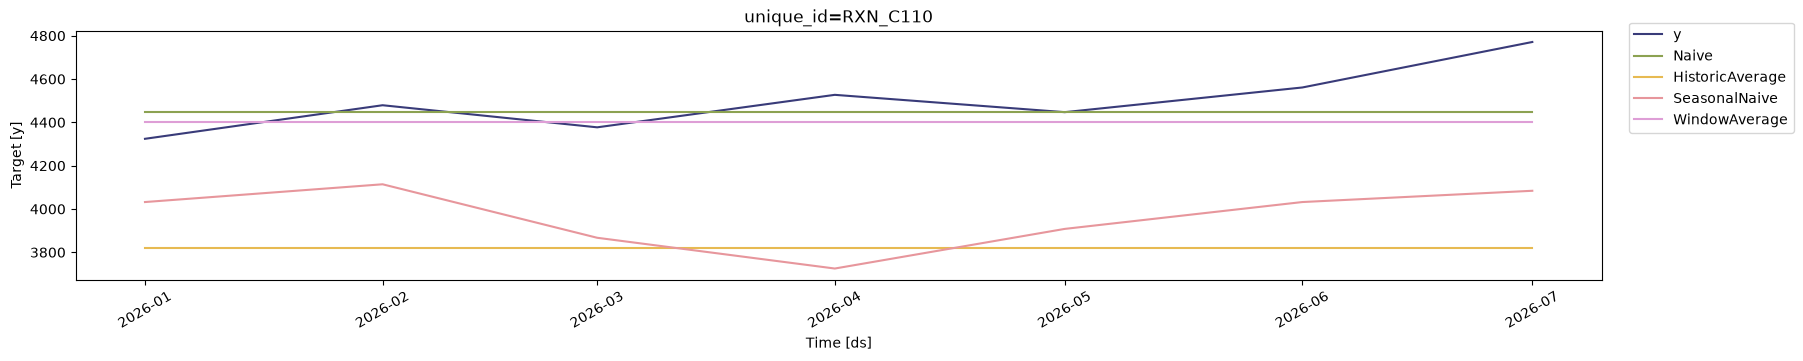

In [7]:
sf.plot(df_sf, predictions, max_insample_length=7 )

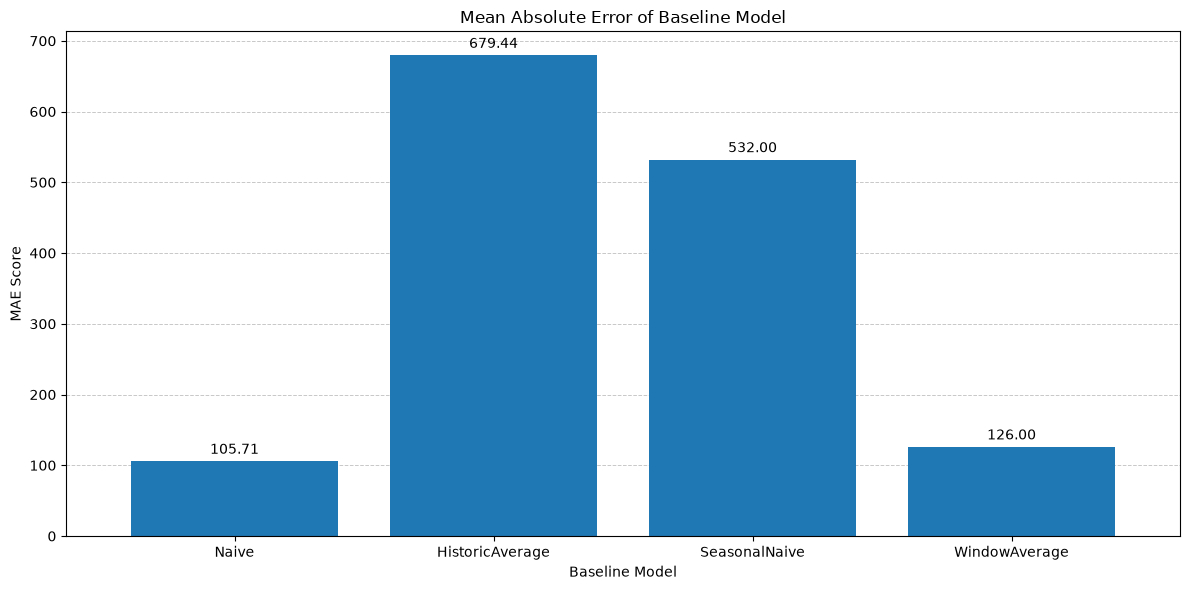

In [8]:
# merge both predictions and actual values
merged_pred = pd.merge(test_data, predictions, how='left',  on=['ds', 'unique_id'])


evaluation = evaluate(
    df=merged_pred,
    metrics=[mae]
    
)

evaluation = evaluation.drop(columns=['unique_id', 'metric'])



fig, ax = plt.subplots(figsize=(12, 6))

evaluation.T.plot(
    kind="bar",
    ax=ax,
    width=0.8,
  
)
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3, fontsize=10)

ax.set(
    title="Mean Absolute Error of Baseline Model",
    xlabel="Baseline Model",
    ylabel="MAE Score"
)

ax.set_axisbelow(True)

ax.grid(
    True,
    axis="y",
    linestyle="--",
    linewidth=0.7,
    alpha=0.7
    
)

ax.set_xticklabels(
    ["Naive", "HistoricAverage", "SeasonalNaive", "WindowAverage"],
    rotation=0
)

ax.get_legend().remove()
fig.tight_layout()
plt.show()

In [9]:
# ARIMA & SARIMA model
models = [
    ARIMA(
        order=(0, 1, 0),
        include_drift=True,
        alias="ARIMA with drift"
    ),
    AutoARIMA(
        seasonal=True,
        season_length=12,
        alias="SARIMA"
    ),
    AutoARIMA(
        seasonal=False,
        alias="ARIMA"
    )
]

sf = StatsForecast(
    models=models,
    freq="MS"
)

sf.fit(training_data)

arima_predictions = sf.predict(h=horizon)

arima_eval_df = pd.merge(
    test_data,
    arima_predictions,
    how="left",
    on=["unique_id", "ds"]
)

arima_eval_df

,y,ds,unique_id,ARIMA with drift,SARIMA,ARIMA
0,4324,2026-01-01,RXN_C110,4482.828613,4375.074219,4450.0
1,4479,2026-02-01,RXN_C110,4515.657227,4296.770020,4450.0
2,4377,2026-03-01,RXN_C110,4548.485840,4169.791992,4450.0
3,4527,2026-04-01,RXN_C110,4581.314453,4059.758301,4450.0
4,4447,2026-05-01,RXN_C110,4614.143066,4117.145996,4450.0
5,4561,2026-06-01,RXN_C110,4646.971191,4233.981934,4450.0
6,4771,2026-07-01,RXN_C110,4679.799805,4352.475586,4450.0


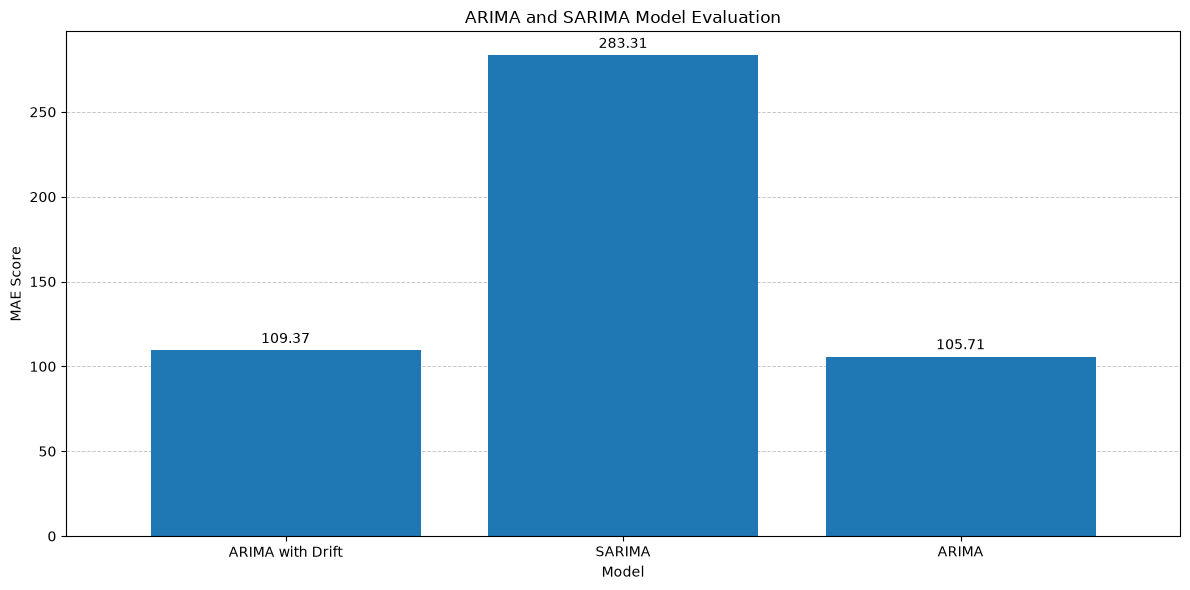

   ARIMA with drift      SARIMA       ARIMA
0        109.371512  283.307199  105.714286


In [10]:
# Evaluate the ARIMA and SARIMA models
arima_evaluation = evaluate(
    df=arima_eval_df,
    metrics=[mae]
)

# Remove unnecessary columns
arima_evaluation = arima_evaluation.drop(
    columns=["unique_id", "metric"]
)

# Plot model evaluation
fig, ax = plt.subplots(figsize=(12, 6))

arima_evaluation.T.plot(
    kind="bar",
    ax=ax,
    width=0.8,
    legend=False
)

# Add MAE labels
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f",
        padding=3,
        fontsize=10
    )

ax.set(
    title="ARIMA and SARIMA Model Evaluation",
    xlabel="Model",
    ylabel="MAE Score"
)

ax.set_axisbelow(True)

ax.grid(
    True,
    axis="y",
    linestyle="--",
    linewidth=0.7,
    alpha=0.7
)

ax.set_xticklabels(
    ["ARIMA with Drift", "SARIMA", "ARIMA"],
    rotation=0
)

fig.tight_layout()
plt.show()
print(arima_evaluation)

In [11]:
fitted_models = sf.fitted_[0]

arima_model = fitted_models[0]
sarima_model = fitted_models[1]

print(type(arima_model))
print(type(sarima_model))

<class 'statsforecast.models.ARIMA'>
<class 'statsforecast.models.AutoARIMA'>


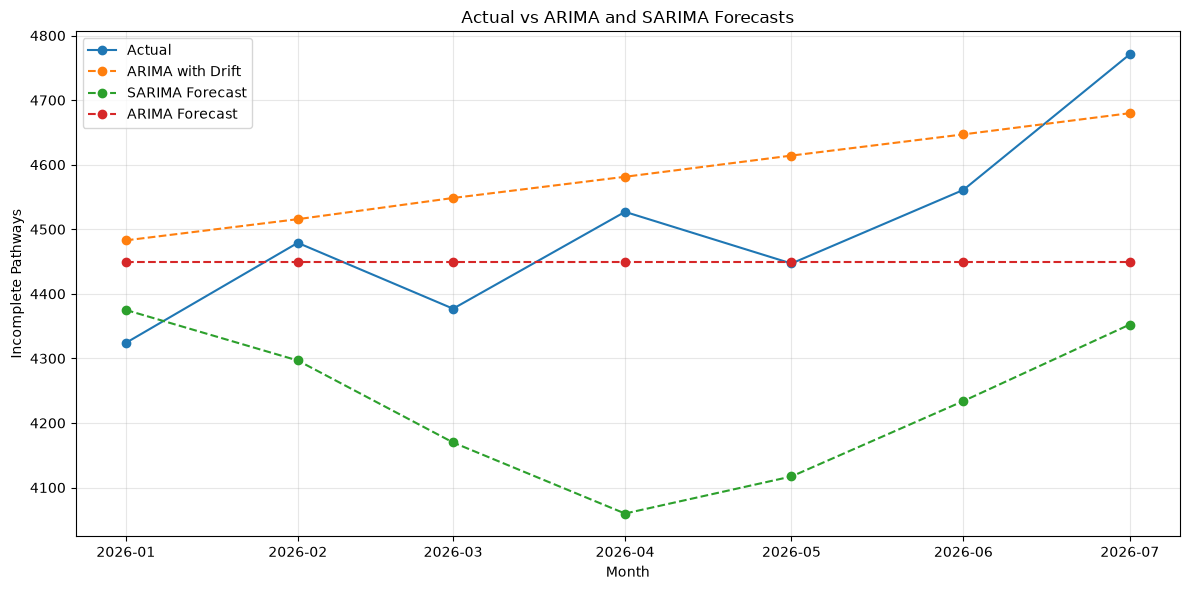

In [12]:
fig, ax = plt.subplots(figsize=(12, 6))

# Actual values
ax.plot(
    arima_eval_df["ds"],
    arima_eval_df["y"],
    marker="o",
    label="Actual"
)

# ARIMA with drift
ax.plot(
    arima_eval_df["ds"],
    arima_eval_df["ARIMA with drift"],
    marker="o",
    linestyle="--",
    label="ARIMA with Drift"
)

# SARIMA
ax.plot(
    arima_eval_df["ds"],
    arima_eval_df["SARIMA"],
    marker="o",
    linestyle="--",
    label="SARIMA Forecast"
)

# ARIMA
ax.plot(
    arima_eval_df["ds"],
    arima_eval_df["ARIMA"],
    marker="o",
    linestyle="--",
    label="ARIMA Forecast"
)

ax.set(
    title="Actual vs ARIMA and SARIMA Forecasts",
    xlabel="Month",
    ylabel="Incomplete Pathways"
)

ax.legend()
ax.grid(alpha=0.3)

fig.tight_layout()
plt.show()

In [13]:
# Evaluating the selected models using cross-validation

models = [
    Naive(),
    WindowAverage(3),
    ARIMA(
        order=(0, 1, 0),
        include_drift=True,
        alias="ARIMA with Drift"
    ),
    AutoARIMA( seasonal=True,
            season_length=12,
            alias="SARIMA")
]

sf = StatsForecast(
    models=models,
    freq="MS"
)

cv_df = sf.cross_validation(
    df=training_data,
    h=horizon,
    refit=True,
    step_size=7,
    n_windows=3
)

# Evaluate model performance
cv_evaluate = evaluate(
    cv_df.drop(columns=["cutoff"]),
    metrics=[mae]
)

# Calculate average MAE across validation windows
cv_evaluate = (
    cv_evaluate
    .drop(columns=["unique_id"])
    .groupby("metric")
    .mean()
    .reset_index()
)

print(cv_evaluate)

  metric       Naive  WindowAverage  ARIMA with Drift      SARIMA
0    mae  205.714279     226.666687        232.142853  150.105728


In [27]:
# use the statsforecast naive model for final prediction
sf = StatsForecast(
    models=[Naive()],
    freq="MS"
)

# Fit using all available historical data
sf.fit(df_sf)

# Generate six-month forecast with prediction intervals
forecast = sf.predict(
    h=6,
    level=[80, 95]
)

forecast.to_csv(ANALYTICAL_DATA_PATH/ "forecast.csv",  index=False)

print(forecast)

  unique_id         ds   Naive  Naive-lo-80  Naive-lo-95  Naive-hi-80  \
0  RXN_C110 2026-08-01  4771.0  4593.161133  4499.018555  4948.838867   
1  RXN_C110 2026-09-01  4771.0  4519.497559  4386.360352  5022.502441   
2  RXN_C110 2026-10-01  4771.0  4462.973633  4299.914551  5079.026367   
3  RXN_C110 2026-11-01  4771.0  4415.321777  4227.037109  5126.678223   
4  RXN_C110 2026-12-01  4771.0  4373.339844  4162.831055  5168.660156   
5  RXN_C110 2027-01-01  4771.0  4335.384766  4104.784180  5206.615234   

   Naive-hi-95  
0  5042.981445  
1  5155.639648  
2  5242.085449  
3  5314.962891  
4  5379.168945  
5  5437.215820  


In [15]:
from statsforecast import StatsForecast
from statsforecast.models import Naive

sf = StatsForecast(
    models=[Naive()],
    freq="MS"
)

cv_intervals = sf.cross_validation(
    df=training_data,
    h=7,
    step_size=7,
    n_windows=3,
    level=[80, 95]
)

cv_intervals.head()

,unique_id,ds,cutoff,y,Naive,Naive-lo-80,Naive-lo-95,Naive-hi-80,Naive-hi-95
0,RXN_C110,2024-04-01,2024-03-01,3637.0,3817.0,3667.853027,3588.899658,3966.146973,4045.100342
1,RXN_C110,2024-05-01,2024-03-01,3534.0,3817.0,3606.074463,3494.417236,4027.925537,4139.582520
2,RXN_C110,2024-06-01,2024-03-01,3601.0,3817.0,3558.669922,3421.918457,4075.330078,4212.081543
3,RXN_C110,2024-07-01,2024-03-01,3725.0,3817.0,3518.706299,3360.799072,4115.293945,4273.200684
4,RXN_C110,2024-08-01,2024-03-01,3849.0,3817.0,3483.497559,3306.951904,4150.502441,4327.048340


In [16]:
cv_intervals["covered_80"] = (
    (cv_intervals["y"] >= cv_intervals["Naive-lo-80"]) &
    (cv_intervals["y"] <= cv_intervals["Naive-hi-80"])
)

cv_intervals["covered_95"] = (
    (cv_intervals["y"] >= cv_intervals["Naive-lo-95"]) &
    (cv_intervals["y"] <= cv_intervals["Naive-hi-95"])
)

In [17]:
coverage_80 = cv_intervals["covered_80"].mean() * 100
coverage_95 = cv_intervals["covered_95"].mean() * 100

print("80% Interval Coverage:", coverage_80)
print("95% Interval Coverage:", coverage_95)

80% Interval Coverage: 71.42857142857143
95% Interval Coverage: 95.23809523809523


In [18]:
cv_intervals

,unique_id,ds,cutoff,y,Naive,Naive-lo-80,Naive-lo-95,Naive-hi-80,Naive-hi-95,covered_80,covered_95
0,RXN_C110,2024-04-01,2024-03-01,3637.0,3817.0,3667.853027,3588.899658,3966.146973,4045.100342,False,True
1,RXN_C110,2024-05-01,2024-03-01,3534.0,3817.0,3606.074463,3494.417236,4027.925537,4139.582520,False,True
2,RXN_C110,2024-06-01,2024-03-01,3601.0,3817.0,3558.669922,3421.918457,4075.330078,4212.081543,True,True
3,RXN_C110,2024-07-01,2024-03-01,3725.0,3817.0,3518.706299,3360.799072,4115.293945,4273.200684,True,True
4,RXN_C110,2024-08-01,2024-03-01,3849.0,3817.0,3483.497559,3306.951904,4150.502441,4327.048340,True,True
5,RXN_C110,2024-09-01,2024-03-01,3887.0,3817.0,3451.666260,3258.270264,4182.333496,4375.729492,True,True
6,RXN_C110,2024-10-01,2024-03-01,4021.0,3817.0,3422.394531,3213.502930,4211.605469,4420.497070,True,True
7,RXN_C110,2024-11-01,2024-10-01,4026.0,4021.0,3871.110352,3791.763672,4170.889648,4250.236328,True,True
8,RXN_C110,2024-12-01,2024-10-01,3929.0,4021.0,3809.024170,3696.810791,4232.976074,4345.189453,True,True
9,RXN_C110,2025-01-01,2024-10-01,4032.0,4021.0,3761.383545,3623.950928,4280.616211,4418.049316,True,True


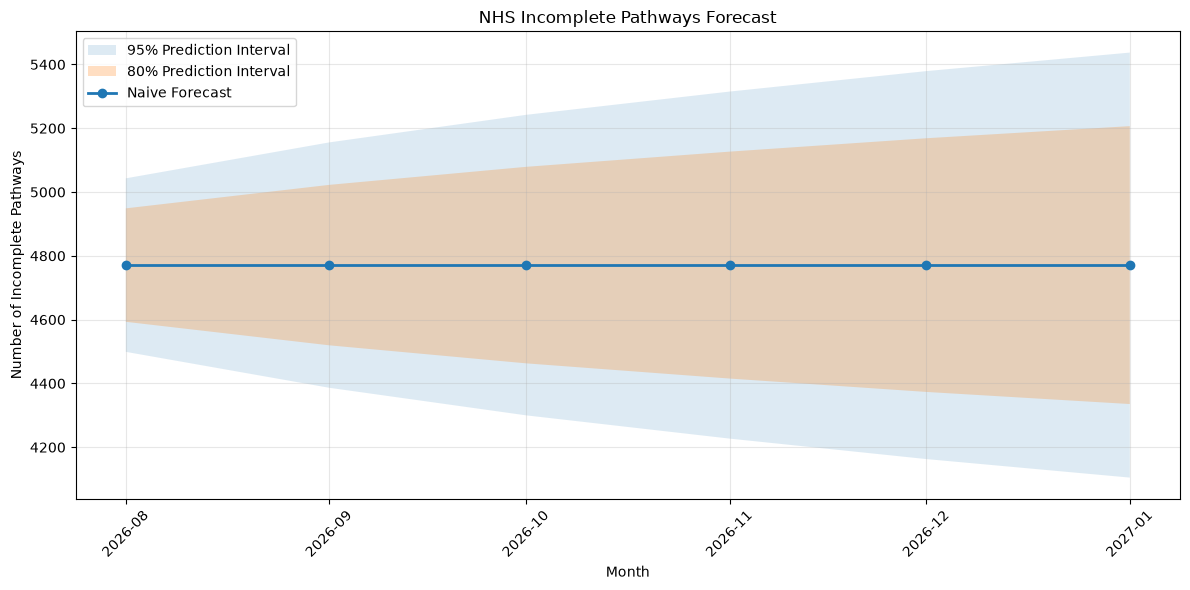

In [19]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

# 95% prediction interval
plt.fill_between(
    forecast["ds"],
    forecast["Naive-lo-95"],
    forecast["Naive-hi-95"],
    alpha=0.15,
    label="95% Prediction Interval"
)

# 80% prediction interval
plt.fill_between(
    forecast["ds"],
    forecast["Naive-lo-80"],
    forecast["Naive-hi-80"],
    alpha=0.25,
    label="80% Prediction Interval"
)

# Point forecast
plt.plot(
    forecast["ds"],
    forecast["Naive"],
    marker="o",
    linewidth=2,
    label="Naive Forecast"
)

plt.title("NHS Incomplete Pathways Forecast")
plt.xlabel("Month")
plt.ylabel("Number of Incomplete Pathways")

plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
